# 02 Descriptive analysis: how sellers differ (Q1)

Q1: How do sellers differ in order volume, late carrier handover rates and the number of late handovers?

This notebook builds the descriptive analysis agreed in `notebooks/descriptive_analysis.markdown`. Each item follows the same pattern: the table the chart is drawn from, the chart, and an explanation. Charts are saved to `figures/`, named by item number.

| Item | Content | Sellers | Figure |
| --- | --- | --- | --- |
| 1 | Headline numbers | All / above threshold | `q1_01_kpi.png` |
| 2 | Concentration of late orders (Pareto) | All | `q1_02a_pareto_curve.png`, `q1_02b_top20_sellers.png` |
| 3 | Distribution of seller late rates | Above threshold | `q1_03a_late_rate_histogram.png`, `q1_03b_late_rate_bands.png` |
| 4 | Why a threshold is needed (funnel scatter) | All, on purpose | `q1_04_funnel.png` |
| 5 | Gap to the same-month benchmark | Above threshold | Table only |
| 6 | Monthly platform late rate | All (order-level) | `q1_06_monthly_trend.png` |

Inputs: `Data/Clean/seller_metrics.csv` and `Data/Clean/monthly_benchmark.csv`, created by `01_cleaning.ipynb`. Run from the `notebooks/` folder. Numbers quoted in the explanations are for a threshold of 20 orders; the tables and charts update automatically if `MIN_ORDERS` changes.

### Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import FuncFormatter, MultipleLocator, PercentFormatter

data_dir = Path("../Data/Clean")
figure_dir = Path("../figures")
figure_dir.mkdir(parents=True, exist_ok=True)

# Minimum orders for charts that compare sellers' late rates. Set by the clustering team; 20 until then.
MIN_ORDERS = 20

# Chart style.
INK, INK_2, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#8a8984", "#fcfcfb", "#e6e5e0"
BLUE, LIGHT_BLUE = "#2a6f97", "#9cc3dc"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#bdbcb6",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.titlecolor": INK,
    "axes.labelcolor": INK_2,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "grid.color": GRID,
    "axes.axisbelow": True,
})

def save_figure(fig, name):
    fig.savefig(figure_dir / name, dpi=200, bbox_inches="tight", facecolor=SURFACE)
    plt.show()

In [2]:
sellers = pd.read_csv(data_dir / "seller_metrics.csv")
months = pd.read_csv(data_dir / "monthly_benchmark.csv")

total_orders = sellers["order_volume"].sum()
total_late = sellers["late_orders"].sum()
platform_rate = total_late / total_orders
large_sellers = sellers.loc[sellers["order_volume"].ge(MIN_ORDERS)].copy()

print(f"Sellers: {len(sellers):,}; orders: {total_orders:,}; late orders: {total_late:,}")
print(f"Platform late rate: {platform_rate:.2%}")
print(f"Sellers with at least {MIN_ORDERS} orders: {len(large_sellers):,}")

Sellers: 2,917; orders: 93,598; late orders: 5,407
Platform late rate: 5.78%
Sellers with at least 20 orders: 778


## Which charts use a minimum-order threshold

A seller's late rate is late orders divided by orders. With very few orders, one order decides the rate, so it can only be 0% or 100%. The table below shows how unstable the rates of small sellers are.

- **All sellers:** charts that count orders, or rank sellers by late-order counts (items 1, 2 and 6). Small sellers barely affect them.
- **All sellers, on purpose:** the funnel scatter (item 4), whose job is to show why a threshold is needed.
- **Above the threshold:** charts that compare sellers' late *rates* (items 3 and 5). Without a threshold, sellers with one or two orders dominate them with rates of 0% or 100%.

The same threshold as the Q2 clustering is used, so both questions describe the same sellers.

In [3]:
volume_groups = pd.cut(
    sellers["order_volume"],
    bins=[0, 1, 4, 9, 19, 49, np.inf],
    labels=["1", "2-4", "5-9", "10-19", "20-49", "50+"],
)
late_rate_by_volume = (
    sellers.groupby(volume_groups, observed=True)
    .agg(
        sellers=("seller_id", "size"),
        share_at_0=("late_rate", lambda rate: rate.eq(0).mean()),
        share_at_100=("late_rate", lambda rate: rate.eq(1).mean()),
        late_rate_std=("late_rate", "std"),
        orders=("order_volume", "sum"),
    )
    .rename_axis("order_volume")
)
late_rate_by_volume["share_of_orders"] = late_rate_by_volume["orders"] / total_orders

display(
    late_rate_by_volume.style.format({
        "share_at_0": "{:.1%}",
        "share_at_100": "{:.1%}",
        "late_rate_std": "{:.2f}",
        "orders": "{:,}",
        "share_of_orders": "{:.1%}",
    })
)

,sellers,share_at_0,share_at_100,late_rate_std,orders,share_of_orders
order_volume,,,,,,
1,537,85.8%,14.2%,0.35,537,0.6%
2-4,665,81.2%,2.4%,0.22,"1,874",2.0%
5-9,516,73.8%,0.4%,0.15,"3,498",3.7%
10-19,421,57.5%,0.2%,0.13,"5,768",6.2%
20-49,372,46.8%,0.0%,0.10,"11,793",12.6%
50+,406,19.0%,0.0%,0.08,"70,128",74.9%


## 1. Headline numbers

### Table behind the chart

In [4]:
never_late_all = sellers["late_orders"].eq(0)
never_late_large = large_sellers["late_orders"].eq(0)
small_among_never_late = sellers.loc[never_late_all, "order_volume"].lt(MIN_ORDERS).mean()

headline = pd.DataFrame(
    [
        ("Orders", f"{total_orders:,}", "Delivered, single-seller\nJan 2017 – Aug 2018"),
        ("Sellers", f"{len(sellers):,}", "All sellers in the sample"),
        ("Late handovers", f"{total_late:,}", "Handed to the carrier after\nthe deadline day"),
        ("Platform late rate", f"{platform_rate:.2%}", "Late handovers ÷ orders"),
        (f"Sellers never late (≥{MIN_ORDERS} orders)", f"{never_late_large.mean():.0%}",
         f"{never_late_large.sum():,} of {len(large_sellers):,} sellers"),
        ("Sellers never late (all sellers)", f"{never_late_all.mean():.0%}",
         f"{never_late_all.sum():,} of {len(sellers):,} sellers, but\n"
         f"{small_among_never_late:.0%} have fewer than {MIN_ORDERS} orders"),
    ],
    columns=["tile", "value", "note"],
)
display(headline)

,tile,value,note
0,Orders,"93,598","Delivered, single-seller\nJan 2017 – Aug 2018"
1,Sellers,"2,917",All sellers in the sample
2,Late handovers,"5,407",Handed to the carrier after\nthe deadline day
3,Platform late rate,5.78%,Late handovers ÷ orders
4,Sellers never late (≥20 orders),32%,251 of 778 sellers
5,Sellers never late (all sellers),64%,"1,875 of 2,917 sellers, but\n87% have fewer th..."


### Chart

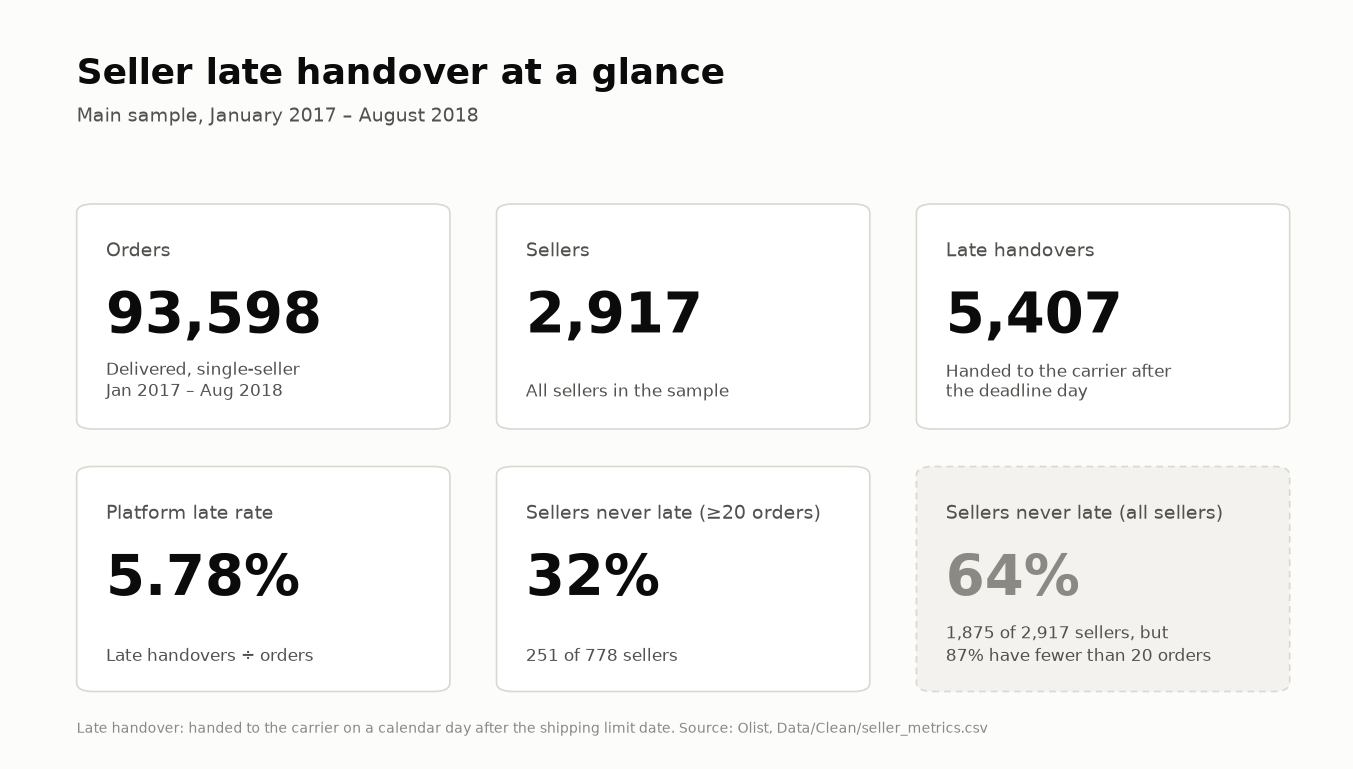

In [5]:
fig = plt.figure(figsize=(13.33, 7.5))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.text(0.05, 0.9, "Seller late handover at a glance", fontsize=26, weight="bold", color=INK)
ax.text(0.05, 0.85, "Main sample, January 2017 – August 2018", fontsize=14, color=INK_2)

width, height, gap_x, gap_y = 0.28, 0.3, 0.035, 0.05
for i, (label, value, note) in enumerate(headline.itertuples(index=False)):
    row, col = divmod(i, 3)
    x = 0.05 + col * (width + gap_x)
    y = 0.44 - row * (height + gap_y)
    caution = i == len(headline) - 1  # The misleading all-sellers figure, shown for contrast.
    ax.add_patch(FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0,rounding_size=0.012",
        facecolor="#f3f2ee" if caution else "white",
        edgecolor="#d9d8d3", linewidth=1.2,
        linestyle=(0, (4, 3)) if caution else "-",
    ))
    ax.text(x + 0.022, y + height - 0.05, label, fontsize=14, color=INK_2, va="top")
    ax.text(x + 0.022, y + height - 0.115, value, fontsize=40, weight="bold",
            color=MUTED if caution else INK, va="top")
    ax.text(x + 0.022, y + 0.035, note, fontsize=12, color=INK_2, va="bottom", linespacing=1.3)

ax.text(0.05, 0.035, "Late handover: handed to the carrier on a calendar day after the shipping limit date. "
        "Source: Olist, Data/Clean/seller_metrics.csv", fontsize=10, color=MUTED)
save_figure(fig, "q1_01_kpi.png")

### Explanation

- **What it shows:** six headline numbers for the main sample. The top row gives the scale (orders, sellers, late handovers); the bottom row gives the rates.
- **How to read it:** the last two tiles are shown side by side on purpose. The grey, dashed tile is the misleading version.
- **Key finding:** 5,407 of 93,598 orders (5.78%) were handed over late. Across all sellers, 64% were never late, but 87% of those sellers have fewer than 20 orders and simply had little chance to be late. Among sellers with at least 20 orders, only 32% were never late.
- **For managers:** late handover is not rare, and late rates of very small sellers are not a reliable basis for judging them.

## 2. Concentration of late orders (Pareto)

A Pareto chart shows whether a problem is concentrated in a few items. Here: are late handovers concentrated in a few sellers? Both versions are produced as options for the PPT role.

### Table behind the charts

The 20 sellers with the most late orders. Ties are broken by `seller_id` so the ranking is reproducible. Charts show these sellers by rank because the full IDs are unreadable on a slide.

In [6]:
ranked = (
    sellers.sort_values(["late_orders", "seller_id"], ascending=[False, True])
    .reset_index(drop=True)
)
ranked["rank"] = ranked.index + 1
ranked["cumulative_share_of_sellers"] = ranked["rank"] / len(ranked)
ranked["cumulative_share_of_late_orders"] = ranked["late_orders"].cumsum() / total_late

top_20 = ranked.head(20)
display(
    top_20[["rank", "seller_id", "order_volume", "late_orders", "late_rate",
            "benchmark_late_rate", "late_rate_gap_pp", "cumulative_share_of_late_orders"]]
    .style.format({
        "late_rate": "{:.1%}",
        "benchmark_late_rate": "{:.1%}",
        "late_rate_gap_pp": "{:+.1f}",
        "cumulative_share_of_late_orders": "{:.1%}",
    })
    .hide(axis="index")
)

for n in [10, 20, 50]:
    print(f"Top {n} sellers ({n / len(sellers):.1%} of sellers): "
          f"{ranked.loc[n - 1, 'cumulative_share_of_late_orders']:.1%} of late orders")
ever_late = ranked["late_orders"].gt(0).sum()
print(f"Sellers with at least one late order: {ever_late:,} ({ever_late / len(sellers):.0%})")

rank,seller_id,order_volume,late_orders,late_rate,benchmark_late_rate,late_rate_gap_pp,cumulative_share_of_late_orders
1,7c67e1448b00f6e969d365cea6b010ab,963,189,19.6%,5.7%,+13.9,3.5%
2,1025f0e2d44d7041d6cf58b6550e0bfa,869,115,13.2%,5.3%,+7.9,5.6%
3,88460e8ebdecbfecb5f9601833981930,224,107,47.8%,5.9%,+41.9,7.6%
4,06a2c3af7b3aee5d69171b0e14f0ee87,369,102,27.6%,5.0%,+22.6,9.5%
5,8160255418d5aaa7dbdc9f4c64ebda44,352,80,22.7%,6.2%,+16.5,11.0%
6,4a3ca9315b744ce9f8e9374361493884,1658,64,3.9%,5.7%,-1.9,12.2%
7,3d871de0142ce09b7081e2b9d1733cb1,1038,63,6.1%,5.7%,+0.3,13.3%
8,7aa4334be125fcdd2ba64b3180029f14,211,56,26.5%,5.7%,+20.9,14.4%
9,1f50f920176fa81dab994f9023523100,1356,54,4.0%,5.9%,-1.9,15.4%
10,2eb70248d66e0e3ef83659f71b244378,185,54,29.2%,4.8%,+24.4,16.3%


Top 10 sellers (0.3% of sellers): 16.3% of late orders
Top 20 sellers (0.7% of sellers): 24.5% of late orders
Top 50 sellers (1.7% of sellers): 40.6% of late orders
Sellers with at least one late order: 1,042 (36%)


### 2A. Cumulative curve

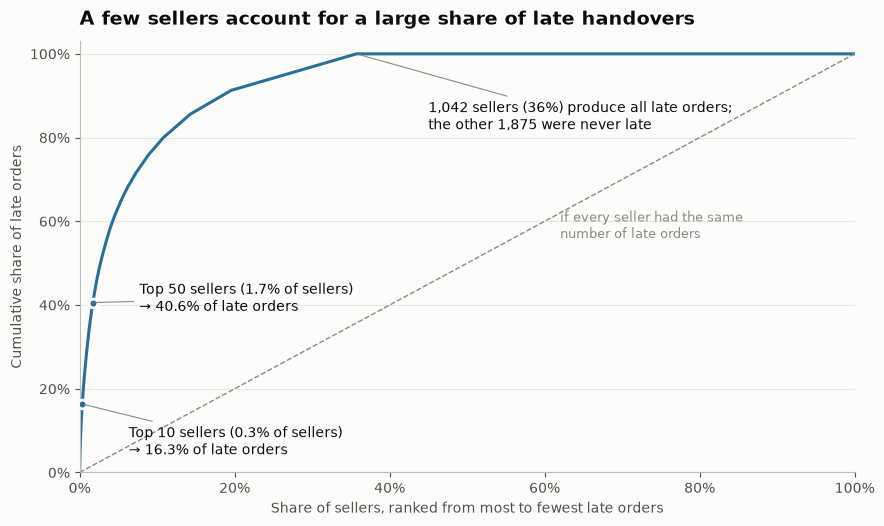

In [7]:
ever_late_sellers = ranked.loc[ranked["late_orders"].gt(0)]

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.plot(
    np.r_[0, ever_late_sellers["cumulative_share_of_sellers"], 1],
    np.r_[0, ever_late_sellers["cumulative_share_of_late_orders"], 1],
    color=BLUE, linewidth=2.2,
)
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--")
ax.text(0.62, 0.56, "if every seller had the same\nnumber of late orders", color=MUTED, fontsize=9)

for n, offset in [(10, -0.12), (50, -0.02)]:
    x, y = ranked.loc[n - 1, ["cumulative_share_of_sellers", "cumulative_share_of_late_orders"]]
    ax.scatter([x], [y], s=40, color=BLUE, zorder=3, edgecolor=SURFACE, linewidth=2)
    ax.annotate(f"Top {n} sellers ({x:.1%} of sellers)\n→ {y:.1%} of late orders",
                (x, y), xytext=(x + 0.06, y + offset), fontsize=10, color=INK,
                arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))

x = ever_late / len(sellers)
ax.annotate(f"{ever_late:,} sellers ({x:.0%}) produce all late orders;\n"
            f"the other {len(sellers) - ever_late:,} were never late",
            (x, 1), xytext=(0.45, 0.82), fontsize=10, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.03)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Share of sellers, ranked from most to fewest late orders")
ax.set_ylabel("Cumulative share of late orders")
ax.grid(axis="y")
ax.set_title("A few sellers account for a large share of late handovers", pad=12)
save_figure(fig, "q1_02a_pareto_curve.png")

**Explanation**

- **What it shows:** sellers ranked from most to fewest late orders; the curve adds up their share of all late orders.
- **How to read it:** the further the curve sits above the dashed diagonal, the more concentrated late handovers are.
- **Key finding:** the top 10 sellers (0.3% of sellers) account for 16.3% of late orders, and the top 50 (1.7%) for 40.6%. Only 1,042 sellers (36%) were ever late, so the curve reaches 100% at 36% of sellers.
- **For managers:** monitoring a small group of sellers addresses a large share of late handovers.

### 2B. Top 20 sellers by late orders

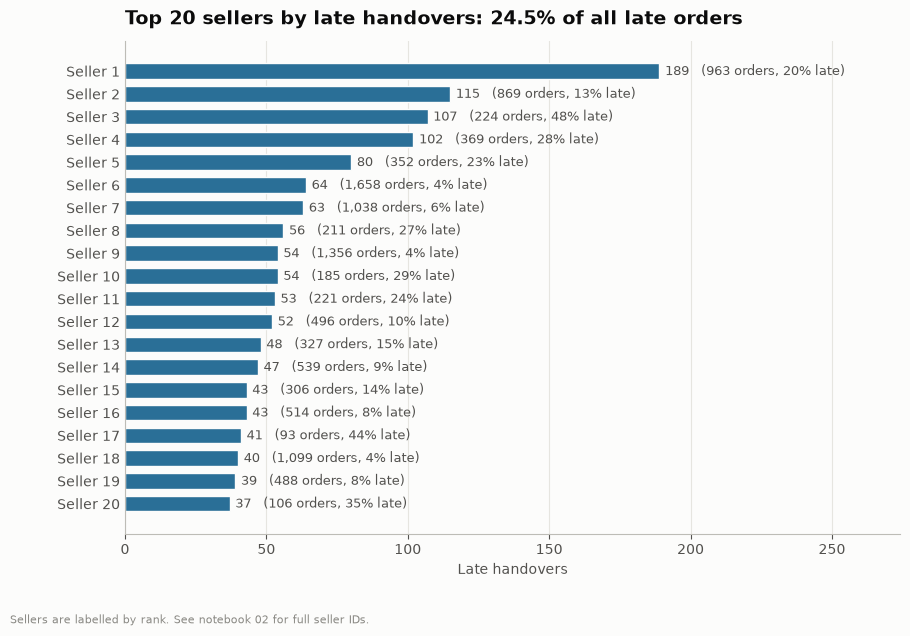

Top 20 sellers below the platform rate: 3
Top 20 sellers more than 5 pp above their same-month benchmark: 12


In [8]:
bars = top_20.iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6.4))
ax.barh([f"Seller {rank}" for rank in bars["rank"]], bars["late_orders"],
        color=BLUE, height=0.68, edgecolor=SURFACE, linewidth=1)
for y, row in enumerate(bars.itertuples()):
    ax.text(row.late_orders + 2, y,
            f"{row.late_orders}   ({row.order_volume:,} orders, {row.late_rate:.0%} late)",
            va="center", fontsize=9, color=INK_2)

ax.set_xlim(0, bars["late_orders"].max() * 1.45)
ax.set_xlabel("Late handovers")
ax.tick_params(axis="y", length=0)
ax.grid(axis="x")
ax.set_title(f"Top 20 sellers by late handovers: "
             f"{top_20['late_orders'].sum() / total_late:.1%} of all late orders", pad=12)
fig.text(0.01, -0.03, "Sellers are labelled by rank. See notebook 02 for full seller IDs.", fontsize=8, color=MUTED)
save_figure(fig, "q1_02b_top20_sellers.png")

print(f"Top 20 sellers below the platform rate: {top_20['late_rate'].lt(platform_rate).sum()}")
print(f"Top 20 sellers more than 5 pp above their same-month benchmark: {top_20['late_rate_gap_pp'].gt(5).sum()}")

**Explanation**

- **What it shows:** the 20 sellers with the most late orders, labelled with their order volume and late rate.
- **How to read it:** bar length is the number of late orders; the label shows whether the seller is large, slow, or both.
- **Key finding:** the top 20 sellers account for 24.5% of late orders, but they are two different kinds of seller. Some are large and close to the platform rate (for example 1,658 orders at 4% late; 3 of the 20 are below the platform rate). Others are mid-sized and very late (for example 224 orders at 48% late; 12 of the 20 are more than 5 pp above their same-month benchmark).
- **For managers:** the number of late orders alone mixes "large but punctual" sellers with "genuinely slow" ones, which need different actions. Q2 groups sellers using their late handover rate and the log-transformed number of late handovers.

## 3. Distribution of seller late rates

Sellers with at least `MIN_ORDERS` orders. Both versions are produced as options for the PPT role; 3B is recommended for the slide.

### Table behind the charts

In [9]:
band_edges = [-np.inf, 0, platform_rate, 0.10, 0.20, np.inf]
band_labels = [
    "0%",
    f"Above 0% to {platform_rate:.2%} (platform)",
    f"{platform_rate:.2%}–10%",
    "10–20%",
    ">20%",
]
large_sellers["late_rate_band"] = pd.cut(large_sellers["late_rate"], bins=band_edges, labels=band_labels, right=True)

late_rate_bands = (
    large_sellers.groupby("late_rate_band", observed=False)
    .agg(sellers=("seller_id", "size"), late_orders=("late_orders", "sum"))
)
small_sellers = sellers.loc[sellers["order_volume"].lt(MIN_ORDERS)]
late_rate_bands.loc[f"Sellers with <{MIN_ORDERS} orders (not in the charts)"] = [
    len(small_sellers), small_sellers["late_orders"].sum()
]
late_rate_bands["share_of_late_orders"] = late_rate_bands["late_orders"] / total_late
display(late_rate_bands.style.format({"late_orders": "{:,}", "share_of_late_orders": "{:.1%}"}))

display(
    large_sellers["late_rate"]
    .quantile([0.1, 0.25, 0.5, 0.75, 0.9])
    .rename("late_rate")
    .rename_axis("percentile")
    .to_frame()
    .style.format("{:.1%}")
)

,sellers,late_orders,share_of_late_orders
late_rate_band,,,
0%,251,0,0.0%
Above 0% to 5.78% (platform),290,"1,198",22.2%
5.78%–10%,96,750,13.9%
10–20%,88,"1,282",23.7%
>20%,53,"1,263",23.4%
Sellers with <20 orders (not in the charts),2139,914,16.9%


,late_rate
percentile,
0.100000,0.0%
0.250000,0.0%
0.500000,2.7%
0.750000,7.7%
0.900000,16.2%


### 3A. Histogram

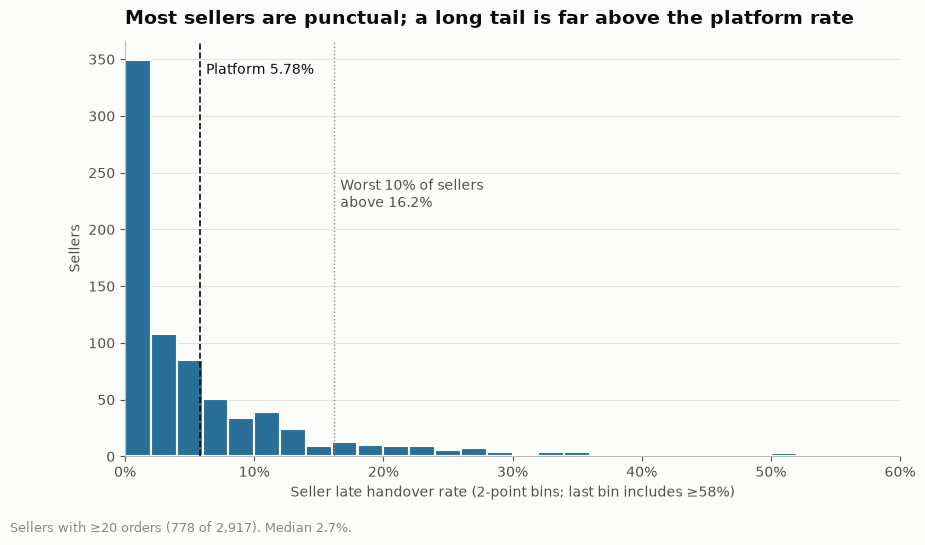

In [10]:
p90 = large_sellers["late_rate"].quantile(0.9)

fig, ax = plt.subplots(figsize=(10, 5.4))
ax.hist(large_sellers["late_rate"].clip(upper=0.599), bins=np.arange(0, 0.62, 0.02),
        color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax.axvline(platform_rate, color=INK, linewidth=1.2, linestyle="--")
ax.text(platform_rate + 0.005, ax.get_ylim()[1] * 0.92, f"Platform {platform_rate:.2%}", color=INK, fontsize=10)
ax.axvline(p90, color=MUTED, linewidth=1, linestyle=":")
ax.text(p90 + 0.005, ax.get_ylim()[1] * 0.6, f"Worst 10% of sellers\nabove {p90:.1%}", color=INK_2, fontsize=10)

ax.set_xlim(0, 0.6)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Seller late handover rate (2-point bins; last bin includes ≥58%)")
ax.set_ylabel("Sellers")
ax.grid(axis="y")
ax.set_title("Most sellers are punctual; a long tail is far above the platform rate", pad=12)
fig.text(0.01, -0.03, f"Sellers with ≥{MIN_ORDERS} orders ({len(large_sellers):,} of {len(sellers):,}). "
         f"Median {large_sellers['late_rate'].median():.1%}.", fontsize=9, color=MUTED)
save_figure(fig, "q1_03a_late_rate_histogram.png")

**Explanation**

- **What it shows:** how many sellers fall in each 2-percentage-point band of late rate.
- **How to read it:** the dashed line is the platform rate (5.78%); the dotted line marks the worst 10% of sellers.
- **Key finding:** most sellers are punctual (median 2.7%, a quarter at 0%), but there is a long right tail: the worst 10% are late on more than 16.2% of orders, and some exceed 30–60%.
- **For managers:** the platform average hides a small group of sellers who are late far more often than the rest.

### 3B. Late-rate bands

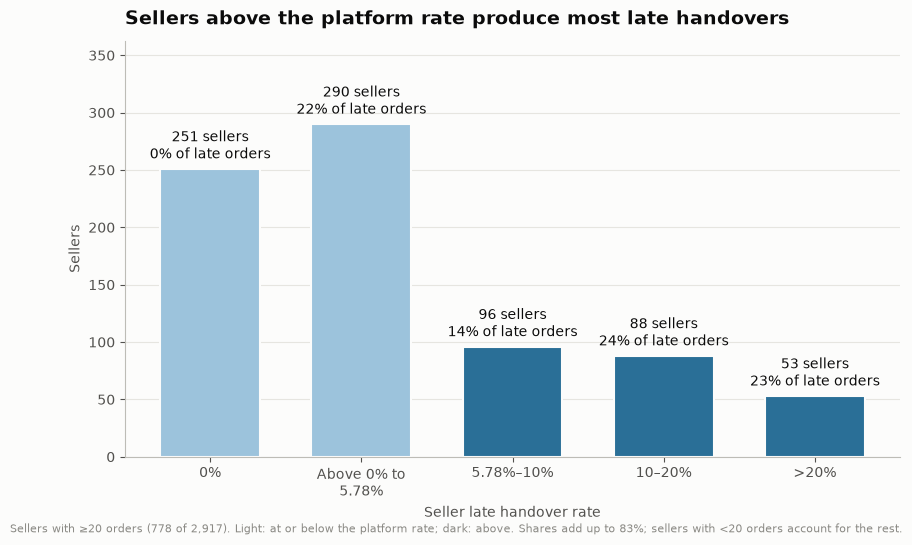

In [11]:
chart_bands = late_rate_bands.loc[band_labels]
labels = ["0%", f"Above 0% to\n{platform_rate:.2%}", f"{platform_rate:.2%}–10%", "10–20%", ">20%"]
colors = [LIGHT_BLUE, LIGHT_BLUE, BLUE, BLUE, BLUE]

fig, ax = plt.subplots(figsize=(10, 5.4))
bars = ax.bar(labels, chart_bands["sellers"], color=colors, edgecolor=SURFACE, linewidth=1.5, width=0.66)
for bar, row in zip(bars, chart_bands.itertuples()):
    ax.text(bar.get_x() + bar.get_width() / 2, row.sellers + 5,
            f"{row.sellers} sellers\n{row.share_of_late_orders:.0%} of late orders",
            ha="center", va="bottom", fontsize=10, color=INK)

ax.set_ylim(0, chart_bands["sellers"].max() * 1.25)
ax.set_xlabel("Seller late handover rate")
ax.set_ylabel("Sellers")
ax.grid(axis="y")
ax.set_title("Sellers above the platform rate produce most late handovers", pad=12)
fig.text(0.01, -0.03,
         f"Sellers with ≥{MIN_ORDERS} orders ({len(large_sellers):,} of {len(sellers):,}). Light: at or below the platform rate; "
         f"dark: above. Shares add up to {chart_bands['share_of_late_orders'].sum():.0%}; "
         f"sellers with <{MIN_ORDERS} orders account for the rest.",
         fontsize=8, color=MUTED)
save_figure(fig, "q1_03b_late_rate_bands.png")

**Explanation**

- **What it shows:** sellers grouped into five late-rate bands, with each band's share of all late orders.
- **How to read it:** bar height is the number of sellers; the label shows how much of the late-handover problem that band causes. Light bars are at or below the platform rate, dark bars above it.
- **Key finding:** 541 sellers (70%) are at or below the platform rate and cause 22% of late orders. The 237 sellers above it (30%) cause 61%. Only 53 sellers are late on more than 20% of their orders, yet they cause 23% of late orders. The shares add up to 83% because sellers with fewer than 20 orders (17% of late orders) are not shown.
- **For managers:** the problem sits with a minority of sellers, which supports the Pareto finding from a rate perspective.

## 4. Why a threshold is needed: order volume vs late rate

All sellers, on purpose.

### Table behind the chart

The order-volume groups table from **Which charts use a minimum-order threshold**.

In [12]:
display(
    late_rate_by_volume.style.format({
        "share_at_0": "{:.1%}",
        "share_at_100": "{:.1%}",
        "late_rate_std": "{:.2f}",
        "orders": "{:,}",
        "share_of_orders": "{:.1%}",
    })
)
correlation = np.corrcoef(np.log(large_sellers["order_volume"]), large_sellers["late_rate"])[0, 1]
print(f"Correlation of log order volume and late rate (≥{MIN_ORDERS} orders): {correlation:.3f}")

,sellers,share_at_0,share_at_100,late_rate_std,orders,share_of_orders
order_volume,,,,,,
1,537,85.8%,14.2%,0.35,537,0.6%
2-4,665,81.2%,2.4%,0.22,"1,874",2.0%
5-9,516,73.8%,0.4%,0.15,"3,498",3.7%
10-19,421,57.5%,0.2%,0.13,"5,768",6.2%
20-49,372,46.8%,0.0%,0.10,"11,793",12.6%
50+,406,19.0%,0.0%,0.08,"70,128",74.9%


Correlation of log order volume and late rate (≥20 orders): 0.003


### Chart

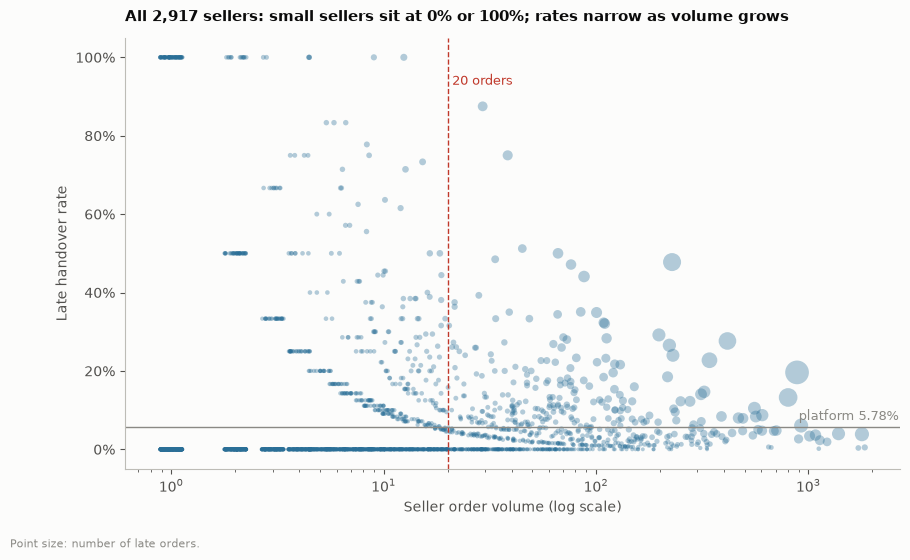

In [13]:
# Small horizontal jitter separates sellers with the same order volume; it does not change the late rate.
rng = np.random.default_rng(0)
x = sellers["order_volume"] * np.exp(rng.uniform(-0.12, 0.12, len(sellers)))

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.scatter(x, sellers["late_rate"], s=8 + sellers["late_orders"] * 1.5,
           alpha=0.35, color=BLUE, edgecolor="none")
ax.axvline(MIN_ORDERS, color="#c0392b", linestyle="--", linewidth=1)
ax.text(MIN_ORDERS * 1.05, 0.93, f"{MIN_ORDERS} orders", color="#c0392b", fontsize=9)
ax.axhline(platform_rate, color=MUTED, linewidth=1)
ax.text(900, platform_rate + 0.017, f"platform {platform_rate:.2%}", color=MUTED, fontsize=9)

ax.set_xscale("log")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Seller order volume (log scale)")
ax.set_ylabel("Late handover rate")
ax.set_title(f"All {len(sellers):,} sellers: small sellers sit at 0% or 100%; rates narrow as volume grows",
             fontsize=11, pad=12)
fig.text(0.01, -0.03, "Point size: number of late orders.", fontsize=8, color=MUTED)
save_figure(fig, "q1_04_funnel.png")

### Explanation

- **What it shows:** every seller as one point: order volume (right = more orders) against late rate (up = later). Larger points have more late orders. The dashed line marks 20 orders.
- **How to read it:** the points form a funnel, wide on the left and narrow on the right. On the left, small sellers sit in horizontal rows at 0%, 50% or 100%, because with 1 or 2 orders those are the only possible rates.
- **Key finding:** the spread of late rates falls from a standard deviation of 0.35 for sellers with 1 order to 0.08 for sellers with 50+ orders. Sellers under 20 orders are 73% of sellers but only 12% of orders. Among sellers with at least 20 orders, log order volume has almost no linear relationship with the late handover rate (r = 0.003).
- **For managers:** late rates of very small sellers should not be used to rank them. Order volume helps managers judge how much a single late order can change a seller’s rate. Q2 uses the number of late handovers to measure how many orders were affected.

## 5. Gap to the same-month benchmark

Sellers with at least `MIN_ORDERS` orders. Table only, no chart: this is a credibility check.

### Table

In [14]:
above_platform = large_sellers["late_rate"].gt(platform_rate).rename("above_platform_rate")
above_benchmark = large_sellers["late_rate_gap_pp"].gt(0).rename("above_same_month_benchmark")
classification = pd.crosstab(above_platform, above_benchmark, margins=True)
display(classification)

changed = (above_platform != above_benchmark).sum()
print(f"Sellers that change classification: {changed} of {len(large_sellers)} ({changed / len(large_sellers):.1%})")

display(
    large_sellers["late_rate_gap_pp"]
    .quantile([0.1, 0.5, 0.9])
    .rename("late_rate_gap_pp")
    .rename_axis("percentile")
    .to_frame()
    .round(1)
)
far_above = large_sellers["late_rate_gap_pp"].gt(5)
print(f"Sellers more than 5 pp above their benchmark: {far_above.sum()}, "
      f"causing {large_sellers.loc[far_above, 'late_orders'].sum() / total_late:.1%} of all late orders")

above_same_month_benchmark,False,True,All
above_platform_rate,,,
False,531,10,541
True,8,229,237
All,539,239,778


Sellers that change classification: 18 of 778 (2.3%)


,late_rate_gap_pp
percentile,
0.1,-6.0
0.5,-3.0
0.9,10.8


Sellers more than 5 pp above their benchmark: 131, causing 44.3% of all late orders


### Explanation

- **What it shows:** sellers classified two ways: above the platform's overall late rate (as in item 3), and above the platform rate in the same months they sold (`late_rate_gap_pp > 0`).
- **How to read it:** the diagonal cells are sellers classified the same way by both comparisons; the off-diagonal cells change sides once months are taken into account.
- **Key finding:** 760 of 778 sellers stayed in the same category. The other 18 (2.3%) changed category when we used the same-month benchmark. 131 sellers are more than 5 pp above their same-month benchmark, and they cause 44.3% of all late orders.
- **For managers and Q&A:** Of the 237 sellers above the overall platform rate, 229 were also above their same-month benchmark.

## 6. Monthly platform late rate

All orders, by purchase month.

### Table behind the chart

In [15]:
display(months.style.format({"orders": "{:,}", "late_orders": "{:,}", "late_rate": "{:.2%}"}).hide(axis="index"))

order_purchase_month,orders,late_orders,late_rate
2017-01,744,138,18.55%
2017-02,"1,628",247,15.17%
2017-03,"2,541",136,5.35%
2017-04,"2,261",121,5.35%
2017-05,"3,498",182,5.20%
2017-06,"3,106",165,5.31%
2017-07,"3,788",137,3.62%
2017-08,"4,134",152,3.68%
2017-09,"4,093",164,4.01%
2017-10,"4,414",199,4.51%


### Chart

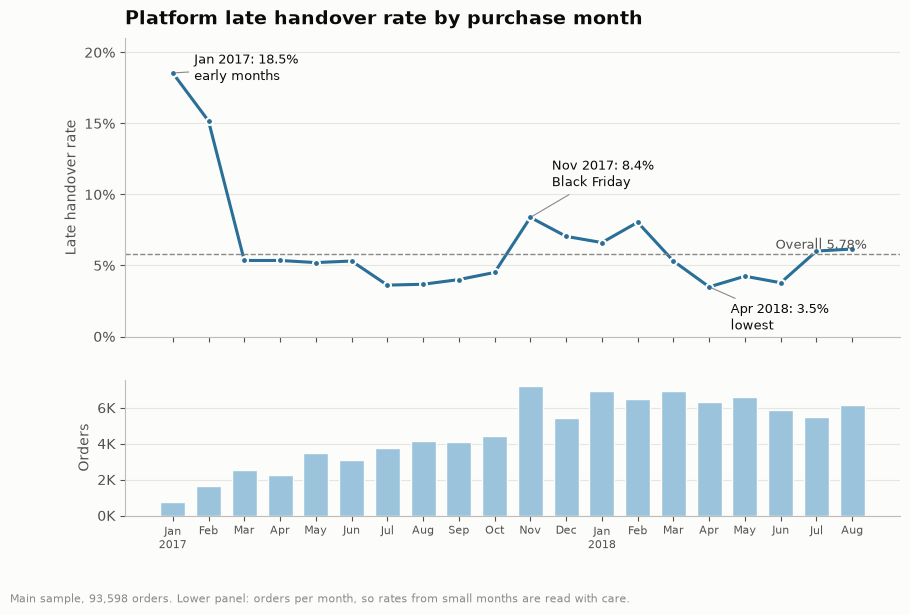

In [16]:
positions = range(len(months))
periods = pd.PeriodIndex(months["order_purchase_month"], freq="M")
tick_labels = [p.strftime("%b\n%Y") if p.month == 1 else p.strftime("%b") for p in periods]

fig, (rate_ax, orders_ax) = plt.subplots(
    2, 1, figsize=(10, 6.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]}
)
rate_ax.plot(positions, months["late_rate"], color=BLUE, linewidth=2.2,
             marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
rate_ax.axhline(platform_rate, color=MUTED, linewidth=1, linestyle="--")
rate_ax.text(len(months) - 0.6, platform_rate + 0.004, f"Overall {platform_rate:.2%}",
             color=INK_2, fontsize=9, ha="right")
for month, text, offset in [
    ("2017-01", "early months", -0.005),
    ("2017-11", "Black Friday", 0.022),
    ("2018-04", "lowest", -0.03),
]:
    i = months.index[months["order_purchase_month"].eq(month)][0]
    rate = months.loc[i, "late_rate"]
    rate_ax.annotate(f"{periods[i].strftime('%b %Y')}: {rate:.1%}\n{text}", (i, rate),
                     xytext=(i + 0.6, rate + offset), fontsize=9, color=INK,
                     arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))
rate_ax.yaxis.set_major_locator(MultipleLocator(0.05))
rate_ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
rate_ax.set_ylim(0, 0.21)
rate_ax.set_ylabel("Late handover rate")
rate_ax.grid(axis="y")
rate_ax.set_title("Platform late handover rate by purchase month", pad=10)

orders_ax.bar(positions, months["orders"], color=LIGHT_BLUE, edgecolor=SURFACE, linewidth=1, width=0.7)
orders_ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1000:.0f}K"))
orders_ax.set_ylabel("Orders")
orders_ax.grid(axis="y")
orders_ax.set_xticks(list(positions))
orders_ax.set_xticklabels(tick_labels, fontsize=8)

fig.text(0.01, -0.03, f"Main sample, {total_orders:,} orders. Lower panel: orders per month, "
         "so rates from small months are read with care.", fontsize=8, color=MUTED)
save_figure(fig, "q1_06_monthly_trend.png")

### Explanation

- **What it shows:** the platform late rate by purchase month (top) and the number of orders in each month (bottom), on the same month axis. They are two panels rather than one chart with two y-axes because the scales differ (0–20% vs 0–7,000 orders).
- **How to read it:** read the panels together; the bars show how many orders each month's rate is based on.
- **Key finding:**
  - January–February 2017 are highest (18.5% and 15.2%), but January has only 744 orders, so that peak is less reliable.
  - November 2017 to February 2018 is a second peak (8.4% in November). November also has the most orders of any month (7,194), which suggests sellers fall behind when demand surges. The link to Black Friday is our interpretation of the timing; the data does not record the cause.
  - April 2018 is the lowest (3.5%). Monthly rates range from 3.5% to 18.5%.
- **For managers:** platform-wide conditions change a lot from month to month, so sellers should be compared with the platform in the same months (item 5).

## Appendix A — Use of Generative AI

I used Claude (Anthropic) to plan and build this notebook.

- **Planning:** Based on the two files, `seller_metrics.csv` and `monthly_benchmark.csv`, Claude offered me some suggestions. I then worked with Claude to confirm, one by one, that these charts met our requirements and aligned with our ideas. Finally, I documented these proposals in the `notebooks/descriptive_analysis.markdown` file.
- **Decision-making:** Claude provided recommendations, but I made the final decisions, and in several places I changed its suggestions:
  - Claude suggested applying a minimum-order threshold to all seller-level charts. I proposed instead to show sellers without a threshold and use a chart to explain why a threshold may be needed, and asked that the notebook explain why some charts use the threshold and others do not.
  - For the headline numbers, Claude suggested choosing between the share of sellers never late across all sellers (64%) and the share among sellers with at least 20 orders (32%). I decided to show both side by side, so the contrast itself explains the threshold.
  - Where two charts suited the same point, such as the Pareto chart, I decided to produce both and let the PPT role choose.
  - Claude first planned to save the tables behind the charts as separate CSV files. I asked instead for each table to be shown inside the notebook before its chart, so readers can see exactly which data each chart is drawn from.
- **Build:** I used Claude to write this notebook based on `descriptive_analysis.markdown`, and to save the charts to the `figures/` directory.